In [1]:
import os
os.chdir("..")
print("Working directory:", os.getcwd())

Working directory: C:\Users\user\real-estate-ml


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
df = pd.read_csv("data/raw/train.csv")
print(f"Dataset: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Dataset: 1460 rows, 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Dataset Overview
The Ames Housing dataset contains 1,460 residential property sales with 81 features covering physical characteristics, quality ratings, and sale conditions.

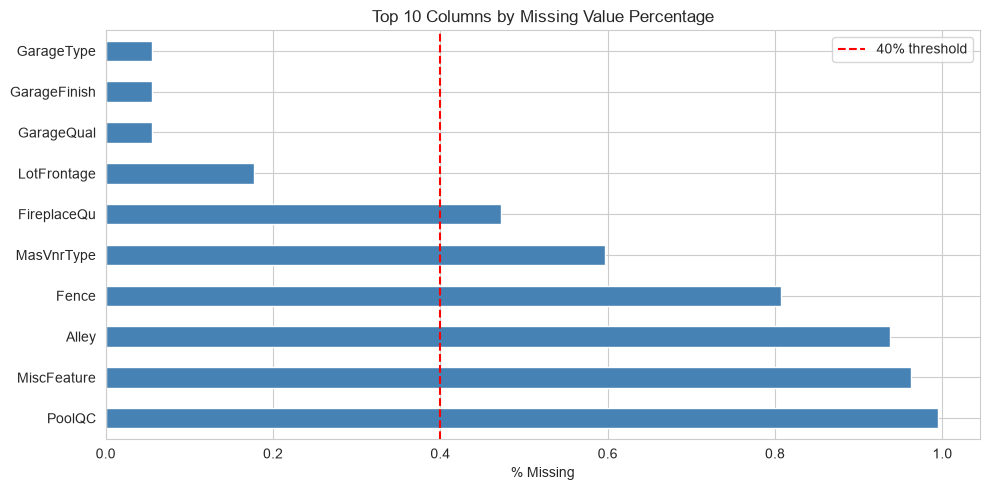

In [5]:
# Missing values — top 10 columns
missing = df.isnull().mean().sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 5))
missing.plot.barh(ax=ax, color="steelblue")
ax.set_title("Top 10 Columns by Missing Value Percentage")
ax.set_xlabel("% Missing")
ax.axvline(x=0.40, color="red", linestyle="--", label="40% threshold")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Target Variable — SalePrice Distribution
Understanding the distribution of SalePrice helps us identify skewness and justify the 3-tier classification approach.

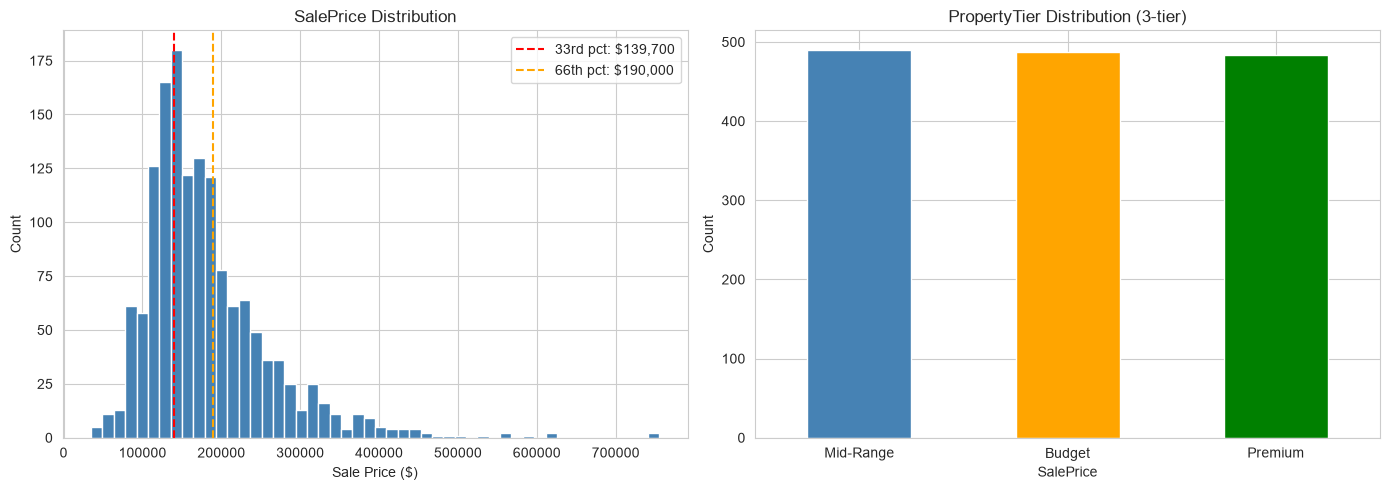


33rd percentile: $139,700
66th percentile: $190,000

Tier counts:
SalePrice
Mid-Range    490
Budget       487
Premium      483
Name: count, dtype: int64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df["SalePrice"], bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("SalePrice Distribution")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Count")

# Add tier boundaries
q33 = df["SalePrice"].quantile(1/3)
q66 = df["SalePrice"].quantile(2/3)
axes[0].axvline(x=q33, color="red", linestyle="--", label=f"33rd pct: ${q33:,.0f}")
axes[0].axvline(x=q66, color="orange", linestyle="--", label=f"66th pct: ${q66:,.0f}")
axes[0].legend()

# Tier distribution
tiers = pd.cut(df["SalePrice"], 
               bins=[0, q33, q66, float("inf")], 
               labels=["Budget", "Mid-Range", "Premium"])
tiers.value_counts().plot.bar(ax=axes[1], color=["steelblue", "orange", "green"])
axes[1].set_title("PropertyTier Distribution (3-tier)")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

print(f"\n33rd percentile: ${q33:,.0f}")
print(f"66th percentile: ${q66:,.0f}")
print(f"\nTier counts:\n{tiers.value_counts()}")

## 3. Feature Correlations
Identifying highly correlated features helps us understand redundancy and justify our correlation filtering threshold (0.90).

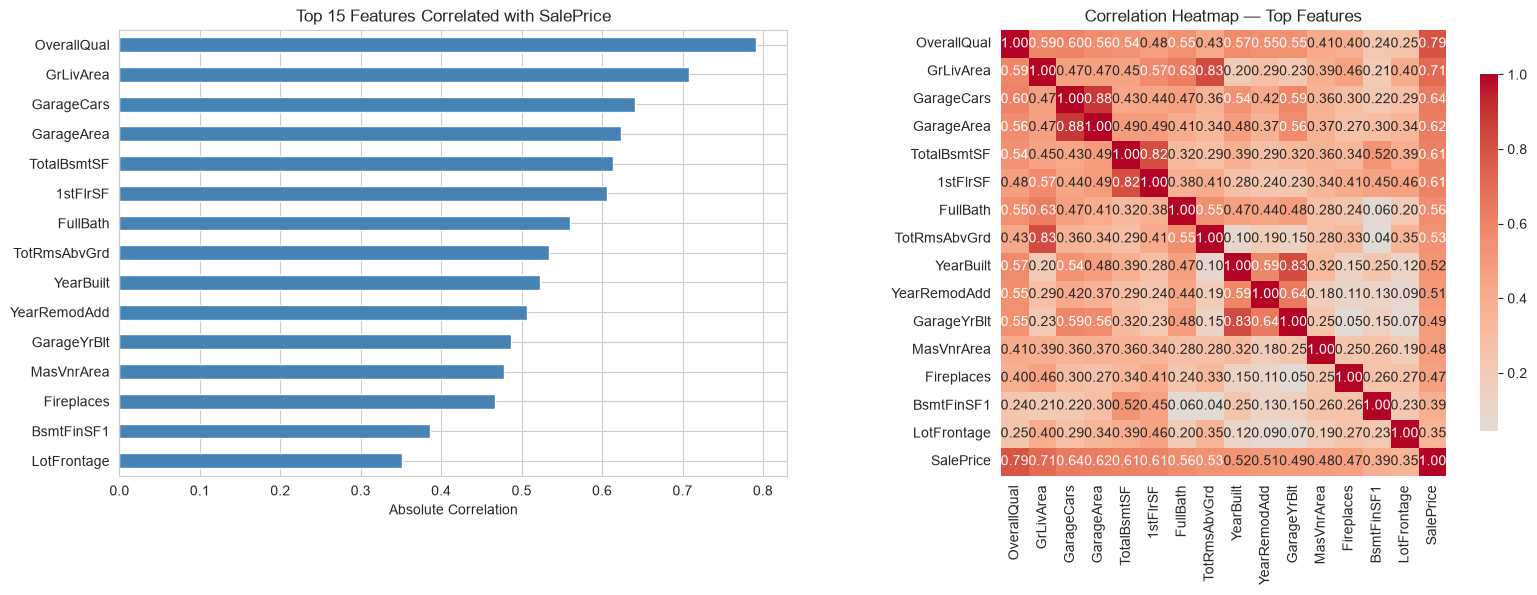

In [7]:
# Top 15 features most correlated with SalePrice
top_corr = df.corr(numeric_only=True)["SalePrice"].abs().sort_values(ascending=False).head(16)[1:]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart — top correlations with SalePrice
top_corr.sort_values().plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Top 15 Features Correlated with SalePrice")
axes[0].set_xlabel("Absolute Correlation")

# Heatmap — correlation between top features
top_features = top_corr.index.tolist()
corr_matrix = df[top_features + ["SalePrice"]].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", 
            center=0, ax=axes[1], square=True, cbar_kws={"shrink": 0.8})
axes[1].set_title("Correlation Heatmap — Top Features")

plt.tight_layout()
plt.show()

## 4. Engineered Features vs SalePrice
Validating that our engineered features have meaningful relationships with the target variable.

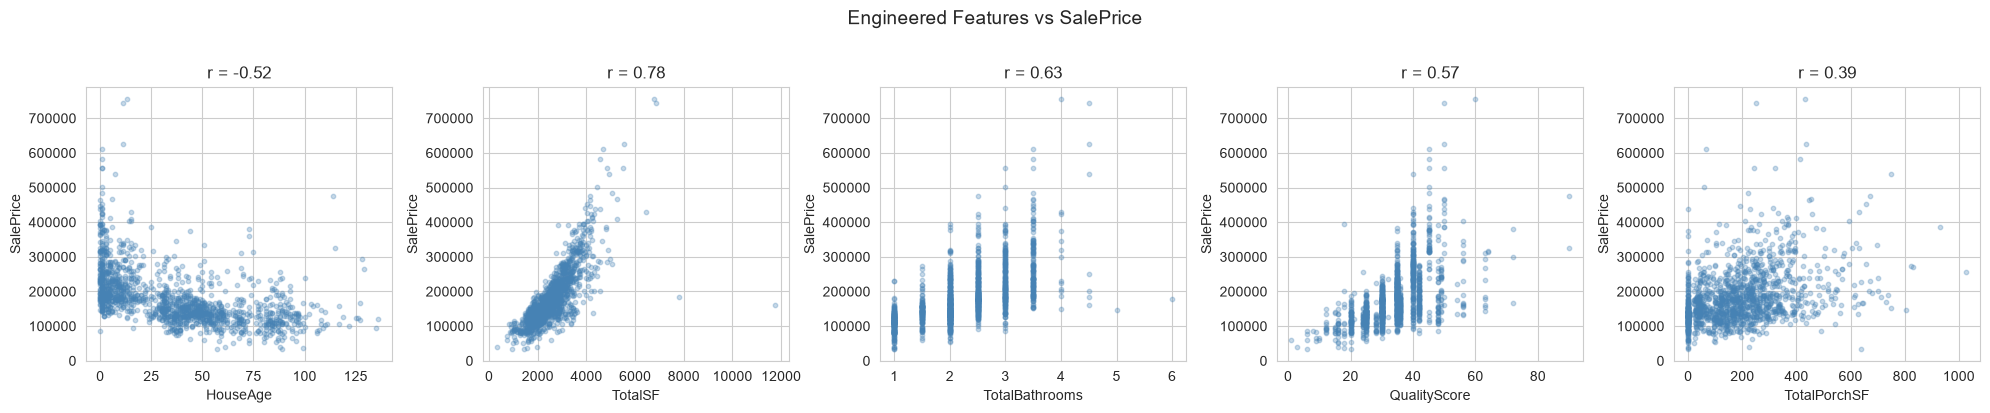

In [8]:
from src.feature_engineering import run_feature_engineering

df_eng, _ = run_feature_engineering(df, fit=True)

eng_features = ["HouseAge", "TotalSF", "TotalBathrooms", "QualityScore", "TotalPorchSF"]

fig, axes = plt.subplots(1, len(eng_features), figsize=(20, 4))

for ax, feat in zip(axes, eng_features):
    ax.scatter(df_eng[feat], df_eng["SalePrice"], alpha=0.3, s=10, color="steelblue")
    ax.set_xlabel(feat)
    ax.set_ylabel("SalePrice")
    corr = df_eng[feat].corr(df_eng["SalePrice"])
    ax.set_title(f"r = {corr:.2f}")

plt.suptitle("Engineered Features vs SalePrice", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 5. SalePrice by Key Categories
Understanding how property prices vary across neighborhoods and building types helps validate the business relevance of the dataset.

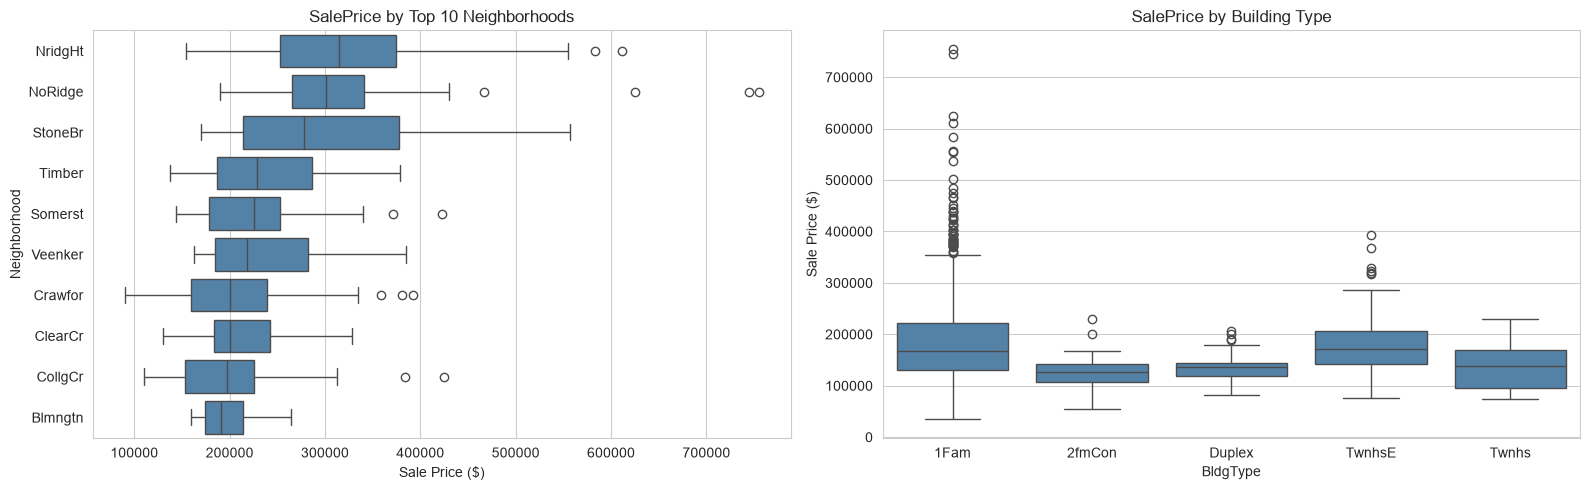

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top 10 neighborhoods by median price
top_neighborhoods = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).head(10).index
df_top = df[df["Neighborhood"].isin(top_neighborhoods)]

sns.boxplot(data=df_top, x="SalePrice", y="Neighborhood", 
            order=top_neighborhoods, ax=axes[0], color="steelblue")
axes[0].set_title("SalePrice by Top 10 Neighborhoods")
axes[0].set_xlabel("Sale Price ($)")

# SalePrice by Building Type
sns.boxplot(data=df, x="BldgType", y="SalePrice", ax=axes[1], color="steelblue")
axes[1].set_title("SalePrice by Building Type")
axes[1].set_ylabel("Sale Price ($)")

plt.tight_layout()
plt.show()